# Clustering de Asentamientos de Saltillo, Coahuila en base a la Generación de Residuos Sólidos Urbanos

**Proyecto Final**

Alumno: David Canales Guajardo

Materia: Machine Learning

Docente: Dra. Jessica Beltrán Márquez

Noviembre 2026

Este proyecto tiene como objetivo aplicar técnicas de aprendizaje automático para analizar la distribución territorial de la generación de residuos sólidos urbanos en Saltillo, Coahuila

Para ello, se estima la población de la ciudad para 2025 mediante modelos de regresión, se utilizan datos poblacionales por asentamiento y se calcula la generación estimada de residuos. Posteriormente, se obtienen puntos representativos de los polígonos geográficos y se aplican algoritmos de clustering para proponer agrupaciones territoriales, buscando una distribución geográficamente compacta y equilibrada en términos de generación de basura

## Librerías

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import ListedColormap
import geopandas as gpd

from pathlib import Path

from sklearn.linear_model import LinearRegression, Ridge 
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.base import clone
from sklearn.cluster import KMeans

import ast

___
## 1. Predicción poblacional de Saltillo

La estimación poblacional es fundamental para la planificación de servicios públicos, especialmente para la recolección de residuos sólidos urbanos

En esta sección se analiza el crecimiento histórico de la población de Saltillo, Coahuila, mediante seis configuraciones de modelos de aprendizaje supervisado:

- Regresión lineal mediante mínimos cuadrados
- Regresión lineal mediante gradiente descendiente
- Regresión polinomial de segundo grado
- Regresión polinomial de tercer grado
- Regresión polinomial de segundo grado con regularización Ridge
- Regresión polinomial de tercer grado con regularización Ridge

Los modelos se entrenan utilizando registros históricos hasta 2020 y se comparan mediante validación temporal, utilizando las métricas MAE, RMSE y R²

Finalmente, se selecciona el modelo con menor MAE para estimar la población de Saltillo en 2025

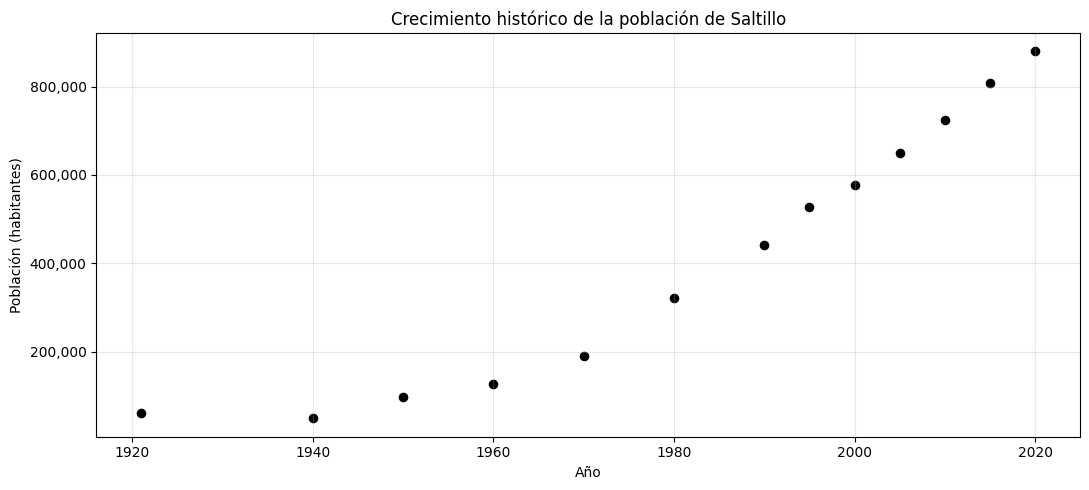

In [31]:
# ============================================================
# CARGA DE POBLACIÓN HISTÓRICA
# ============================================================

Path_POBLACION_HISTORICA = (Path("Recursos") / "Población_Histórica_Saltillo.xlsx")
POBLACION_HISTORICA = pd.read_excel(Path_POBLACION_HISTORICA)
POBLACION_HISTORICA_COPIA = POBLACION_HISTORICA.copy()

# ============================================================
# GRÁFICA HISTÓRICA
# ============================================================

plt.figure(figsize=(11, 5))

plt.scatter(
    POBLACION_HISTORICA_COPIA["Año"],
    POBLACION_HISTORICA_COPIA["Población"],
    s=35,
    color = "black"
)

plt.title("Crecimiento histórico de la población de Saltillo")
plt.xlabel("Año")
plt.ylabel("Población (habitantes)")
plt.grid(alpha=0.3)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# REGRESIONES POBLACIONALES: ENTRENAMIENTO Y EVALUACIÓN
# ============================================================

Datos = POBLACION_HISTORICA_COPIA.copy()
Datos = Datos.sort_values("Año").reset_index(drop=True)

X = (Datos[["Año"]].to_numpy(dtype=float) - 2000) / 10
y = Datos["Población"].to_numpy(dtype=float)


# ------------------------------------------------------------
# Regresión lineal por gradiente descendiente
# ------------------------------------------------------------
def entrenar_gradiente(X_train, y_train, tasa=0.1, iteraciones=5000):

    media_x = X_train.mean(axis=0)
    escala_x = X_train.std(axis=0)
    escala_x[escala_x == 0] = 1

    X_norm = (X_train - media_x) / escala_x

    escala_y = 1_000_000
    y_norm = y_train / escala_y

    X_bias = np.c_[np.ones(len(X_norm)), X_norm]
    theta = np.zeros(X_bias.shape[1])

    historial = []

    for _ in range(iteraciones):

        predicciones = X_bias @ theta
        errores = predicciones - y_norm

        costo = np.mean(errores ** 2) / 2
        historial.append(costo)

        gradiente = (X_bias.T @ errores) / len(y_norm)
        theta -= tasa * gradiente

    return {
        "theta": theta,
        "media_x": media_x,
        "escala_x": escala_x,
        "escala_y": escala_y,
        "historial": historial
    }

def predecir_gradiente(modelo, X_test):

    X_norm = (
        (X_test - modelo["media_x"]) / modelo["escala_x"]
    )

    X_bias = np.c_[np.ones(len(X_norm)), X_norm]

    return (
        X_bias @ modelo["theta"]
    ) * modelo["escala_y"]


# ------------------------------------------------------------
# Función para Crear Modelos de Regresiones por Ridge y/o Mínimos cuadrados
# ------------------------------------------------------------
def crear_modelo(grado, ridge=False, alpha=1.0):

    estimador = (
        Ridge(alpha=alpha)
        if ridge else LinearRegression()
    )

    return make_pipeline(
        PolynomialFeatures(
            degree=grado,
            include_bias=False
        ),
        StandardScaler(),
        estimador
    )

# ------------------------------------------------------------
# Modelos de Regresiones por Mínimos Cuadrados
# ------------------------------------------------------------
Modelos = {
    "Lineal - Mínimos cuadrados": crear_modelo(1),
    "Polinomial grado 2": crear_modelo(2),
    "Polinomial grado 3": crear_modelo(3)
}

Alphas = [0.01, 0.1, 1]

def seleccionar_alpha(X_train, y_train, grado):

    resultados = []

    for alpha in Alphas:

        errores = []

        for i in range(4, len(X_train)):

            modelo = crear_modelo(
                grado, ridge=True, alpha=alpha
            )

            modelo.fit(X_train[:i], y_train[:i])

            pred = modelo.predict(X_train[i:i+1])

            errores.append(
                abs(y_train[i] - pred[0])
            )

        if errores:
            resultados.append((np.mean(errores), alpha))

    if not resultados:
        raise ValueError(
            "No hay suficientes datos para seleccionar alpha."
        )

    return min(resultados)[1]


# ============================================================
# VALIDACIÓN TEMPORAL EXTERNA
# ============================================================

Anios_Prueba = [2000, 2005, 2010, 2015, 2020]

Nombres_Modelos = [
    "Lineal - Mínimos cuadrados",
    "Lineal - Gradiente descendiente",
    "Polinomial grado 2",
    "Polinomial grado 3",
    "Polinomial grado 2 - Ridge",
    "Polinomial grado 3 - Ridge"
]

Predicciones_Validacion = {
    nombre: [] for nombre in Nombres_Modelos
}

Reales_Validacion = []

for Anio in Anios_Prueba:

    train = Datos["Año"] < Anio
    test = Datos["Año"] == Anio

    X_train, y_train = X[train], y[train]
    X_test, y_test = X[test], y[test]

    if len(X_train) < 5 or len(X_test) != 1:
        raise ValueError(
            f"Datos insuficientes para evaluar {Anio}."
        )

    Reales_Validacion.append(y_test[0])

# ------------------------------------------------------------
# Lineal y Polinomiales por Mínimos Cuadrados
# ------------------------------------------------------------
    for Nombre, Modelo in Modelos.items():

        modelo = clone(Modelo)
        modelo.fit(X_train, y_train)

        pred = modelo.predict(X_test)[0]
        Predicciones_Validacion[Nombre].append(pred)

# ------------------------------------------------------------
# Lineal por Gradiente Descendiente
# ------------------------------------------------------------
    modelo_gd = entrenar_gradiente(X_train, y_train)
    pred_gd = predecir_gradiente(modelo_gd, X_test)[0]

    Predicciones_Validacion[
        "Lineal - Gradiente descendiente"
    ].append(pred_gd)

# ------------------------------------------------------------
# Polinomiales por Ridge
# ------------------------------------------------------------
    for grado in [2, 3]:

        alpha = seleccionar_alpha(
            X_train, y_train, grado
        )

        modelo = crear_modelo(
            grado, ridge=True, alpha=alpha
        )

        modelo.fit(X_train, y_train)

        Nombre = f"Polinomial grado {grado} - Ridge"

        Predicciones_Validacion[Nombre].append(
            modelo.predict(X_test)[0]
        )


# ============================================================
# MÉTRICAS DE EVALUACIÓN
# ============================================================

Resultados = []

for Nombre in Nombres_Modelos:

    Predichos = Predicciones_Validacion[Nombre]

    MAE = mean_absolute_error(
        Reales_Validacion, Predichos
    )

    RMSE = np.sqrt(
        mean_squared_error(
            Reales_Validacion, Predichos
        )
    )

    R2 = r2_score(
        Reales_Validacion, Predichos
    )

    Resultados.append({
        "Modelo": Nombre,
        "MAE": MAE,
        "RMSE": RMSE,
        "R²": R2
    })

Resultados_Modelos = (
    pd.DataFrame(Resultados)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(Resultados_Modelos.round(3))

Mejor_Modelo = Resultados_Modelos.iloc[0]["Modelo"]

print(f"Mejor modelo según MAE: {Mejor_Modelo}")
print(f"Años evaluados: {Anios_Prueba}")

# ============================================================
# ENTRENAMIENTO FINAL CON TODOS LOS DATOS HASTA 2020
# ============================================================

Modelos_Finales = {}

for Nombre, Modelo in Modelos.items():

    modelo = clone(Modelo)
    modelo.fit(X, y)

    Modelos_Finales[Nombre] = modelo

# Gradiente descendiente
Modelo_GD_Final = entrenar_gradiente(X, y)

# Ridge con alpha seleccionado
Alphas_Finales = {}

for grado in [2, 3]:

    alpha = seleccionar_alpha(X, y, grado)

    modelo = crear_modelo(
        grado, ridge=True, alpha=alpha
    )

    modelo.fit(X, y)

    Nombre = f"Polinomial grado {grado} - Ridge"

    Modelos_Finales[Nombre] = modelo
    Alphas_Finales[Nombre] = alpha


def predecir_modelo(Nombre, X_nuevo):

    if Nombre == "Lineal - Gradiente descendiente":
        return predecir_gradiente(
            Modelo_GD_Final, X_nuevo
        )

    return Modelos_Finales[Nombre].predict(X_nuevo)


# ------------------------------------------------------------
# Predicción para el 2025
# ------------------------------------------------------------

X_2025 = np.array([[(2025 - 2000) / 10]])

Predicciones_2025 = {
    Nombre: float(
        predecir_modelo(Nombre, X_2025)[0]
    )
    for Nombre in Nombres_Modelos
}

Tabla_Predicciones = pd.DataFrame({
    "Modelo": list(Predicciones_2025.keys()),
    "Población estimada 2025": list(
        Predicciones_2025.values()
    )
})

display(Tabla_Predicciones.round(0))

Prediccion_Final = Predicciones_2025[Mejor_Modelo]

print(f"\nModelo seleccionado: {Mejor_Modelo}")
print(f"Población estimada 2025: {Prediccion_Final:,.0f}")
print(f"Alphas Ridge seleccionados: {Alphas_Finales}")


,Modelo,MAE,RMSE,R²
0,Polinomial grado 3 - Ridge,5766.890,6170.787,0.997
1,Polinomial grado 3,20810.132,24335.244,0.949
2,Polinomial grado 2 - Ridge,22110.462,22758.547,0.955
3,Polinomial grado 2,26683.566,27067.411,0.937
4,Lineal - Mínimos cuadrados,122094.022,122463.115,-0.289
5,Lineal - Gradiente descendiente,122094.022,122463.115,-0.289


Mejor modelo según MAE: Polinomial grado 3 - Ridge
Años evaluados: [2000, 2005, 2010, 2015, 2020]


,Modelo,Población estimada 2025
0,Lineal - Mínimos cuadrados,820589.0
1,Lineal - Gradiente descendiente,820589.0
2,Polinomial grado 2,998110.0
3,Polinomial grado 3,967594.0
4,Polinomial grado 2 - Ridge,995587.0
5,Polinomial grado 3 - Ridge,963633.0



Modelo seleccionado: Polinomial grado 3 - Ridge
Población estimada 2025: 963,633
Alphas Ridge seleccionados: {'Polinomial grado 2 - Ridge': 0.01, 'Polinomial grado 3 - Ridge': 0.01}


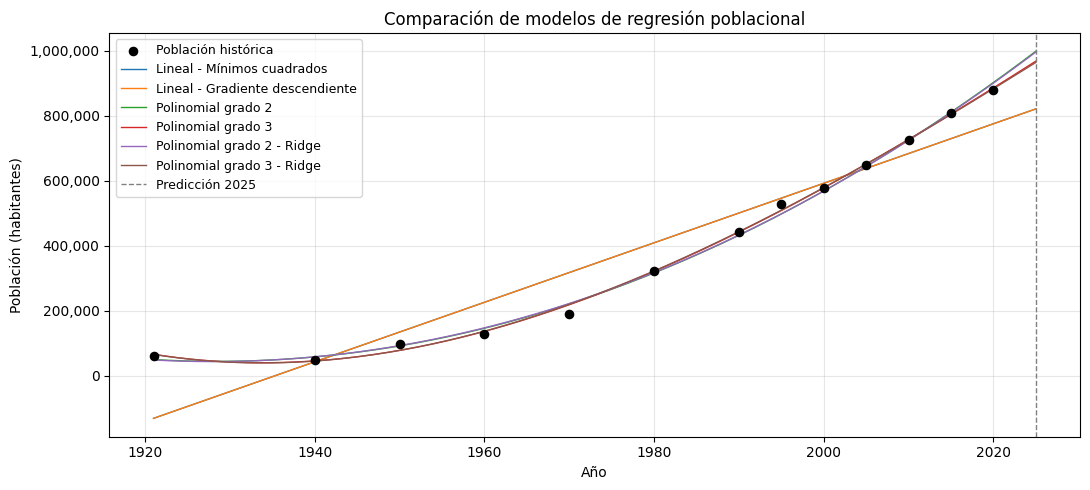

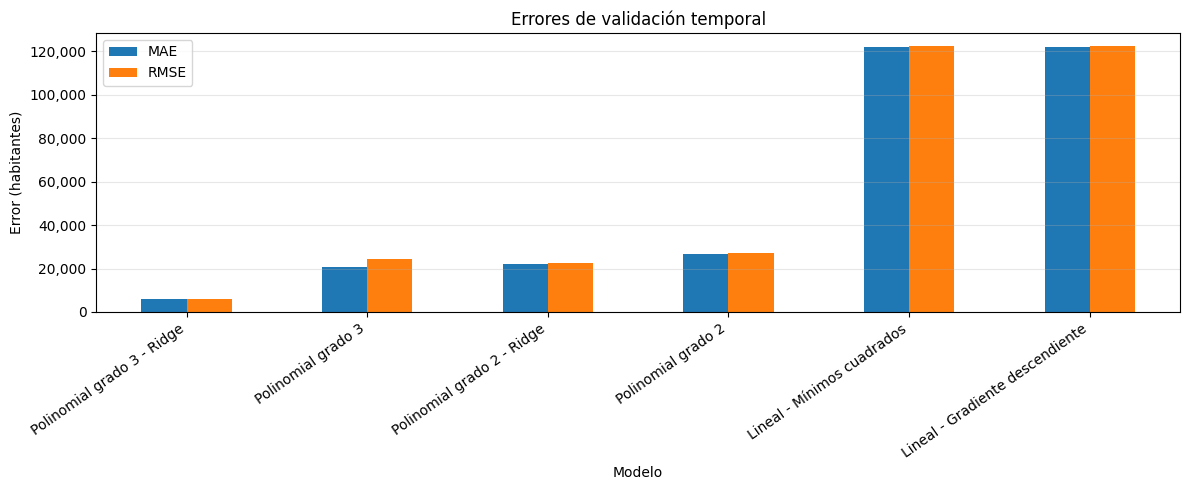

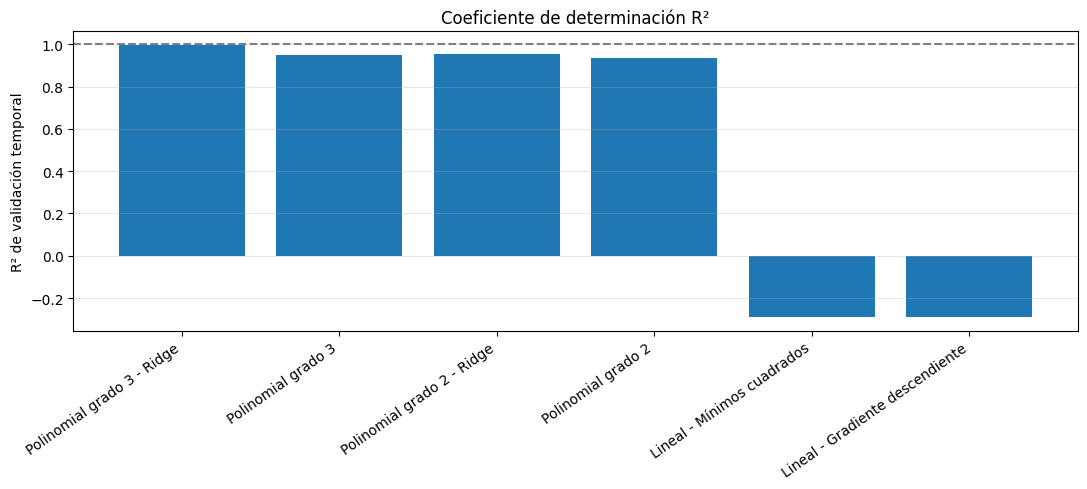

In [35]:
# ============================================================
# GRÁFICA 1: COMPARACIÓN DE LAS SEIS REGRESIONES
# ============================================================

Anios_Grafica = np.linspace(
    Datos["Año"].min(), 2025, 300
)

X_Grafica = (
    Anios_Grafica.reshape(-1, 1) - 2000
) / 10

plt.figure(figsize=(11, 5))

plt.scatter(
    Datos["Año"],
    Datos["Población"],
    color="black",
    s=35,
    label="Población histórica",
    zorder=5
)

for Nombre in Nombres_Modelos:

    pred = predecir_modelo(Nombre, X_Grafica)

    plt.plot(
        Anios_Grafica,
        pred,
        linewidth=1,
        label=Nombre
    )

plt.axvline(
    2025,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="Predicción 2025"
)

plt.title("Comparación de modelos de regresión poblacional")
plt.xlabel("Año")
plt.ylabel("Población (habitantes)")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICA 2: MAE Y RMSE
# ============================================================

ax = Resultados_Modelos.plot.bar(
    x="Modelo",
    y=["MAE", "RMSE"],
    figsize=(12, 5),
    rot=35
)

ax.set_title("Errores de validación temporal")
ax.set_xlabel("Modelo")
ax.set_ylabel("Error (habitantes)")
ax.grid(axis="y", alpha=0.3)
plt.gca().yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
plt.xticks(ha="right")
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICA 3: R²
# ============================================================

plt.figure(figsize=(11, 5))

plt.bar(
    Resultados_Modelos["Modelo"],
    Resultados_Modelos["R²"]
)

plt.axhline(
    1, linestyle="--", color="gray"
)

plt.title("Coeficiente de determinación R²")
plt.ylabel("R² de validación temporal")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

___
## 2. Distribución de la población estimada por asentamiento

Una vez estimada la población total de Saltillo para 2025, se plantea distribuir el crecimiento poblacional de manera proporcional entre los asentamientos, tomando como referencia su población de 2020

Para ello, se utilizó la siguiente fórmula:

$$
P_{i,2025}=P_{i,2020}\times\frac{P_{2025}}{P_{2020}}
$$

Donde:

- $P_{i,2025}$: población estimada del asentamiento $i$ para 2025
- $P_{i,2020}$: población del asentamiento $i$ en 2020
- $P_{2025}$: población total estimada de Saltillo para 2025
- $P_{2020}$: población total de Saltillo en 2020

El ajuste de los datos se trabaja de manera externa al notebook

___
## 3. Estimación de la generación de residuos sólidos urbanos

En esta sección se utilizan los registros históricos de recolección de basura de 2025 y la población estimada de los asentamientos para calcular la cantidad promedio de residuos generados por habitante al día

Para ello, se suma el tonelaje registrado por sector durante el periodo analizado y se divide entre la población atendida y el número de días calendario del periodo, convirtiendo las toneladas a kilogramos

$$
g=\frac{T\times1000}{P\times D}
$$

Donde:
- **g:** promedio diario de residuos recolectados por habitante $\frac{kg \times hab}{día}$
- **T:** toneladas totales recolectadas durante el periodo
- **P:** población total atendida
- **D:** número de días del periodo analizado

In [47]:
# ============================================================
# CARGAR Y SIMPLIFICAR DICCIONARIO DE SECTORES
# ============================================================

Path_SECTORES = (Path("Recursos") / "Diccionario_Sectores_Vespertinos.py")

with open(Path_SECTORES, encoding="utf-8") as archivo:
    codigo = ast.parse(archivo.read())

for nodo in codigo.body:
    if isinstance(nodo, ast.Assign):
        if any(
            isinstance(t, ast.Name)
            and t.id == "SectoresVespertinos"
            for t in nodo.targets
        ):
            diccionario_original = ast.literal_eval(nodo.value)
            break
else:
    raise ValueError("No se encontró SectoresVespertinos")

SECTORES = {
    int(sector): list(dict.fromkeys(datos[0]))
    for sector, datos in diccionario_original.items()
}

print(f"Sectores cargados: {len(SECTORES)}")

Sectores cargados: 70


In [49]:
# ============================================================
# POBLACIÓN ESTIMADA POR SECTOR
# ============================================================

Path_ASENTAMIENTOS = (Path("Recursos") / "Colonias con Datos Sociodemográficos.xlsx")

ASENTAMIENTOS = pd.read_excel(Path_ASENTAMIENTOS)
ASENTAMIENTOS_COPIA = ASENTAMIENTOS.copy()

# ------------------------------------------------------------
# Eliminar filas completamente vacías
# ------------------------------------------------------------
ASENTAMIENTOS_COPIA = ASENTAMIENTOS_COPIA.dropna(
    how="all"
).copy()

ASENTAMIENTOS_COPIA["CVEASEN"] = pd.to_numeric(
    ASENTAMIENTOS_COPIA["CVEASEN"], errors="coerce"
)

ASENTAMIENTOS_COPIA["POBLACIÓN TOTAL"] = pd.to_numeric(
    ASENTAMIENTOS_COPIA["POBLACIÓN TOTAL"], errors="coerce"
)

# ------------------------------------------------------------
# Eliminar registros sin identificador de asentamiento
# ------------------------------------------------------------
ASENTAMIENTOS_COPIA = ASENTAMIENTOS_COPIA.dropna(
    subset=["CVEASEN"]
).copy()

# ------------------------------------------------------------
# Evitar poblaciones duplicadas en el Excel
# ------------------------------------------------------------
if ASENTAMIENTOS_COPIA["CVEASEN"].duplicated().any():
    raise ValueError(
        "Existen claves CVEASEN duplicadas en el Excel."
    )

# ------------------------------------------------------------
# Crear diccionario: asentamiento -> población
# ------------------------------------------------------------
POBLACION_ASENTAMIENTOS = (
    ASENTAMIENTOS_COPIA
    .set_index("CVEASEN")["POBLACIÓN TOTAL"]
    .to_dict()
)

# ------------------------------------------------------------
# Crear relaciones únicas entre sectores y asentamientos
# ------------------------------------------------------------
RELACIONES = pd.DataFrame(
    [
        (sector, asentamiento)
        for sector, asentamientos in SECTORES.items()
        for asentamiento in asentamientos
    ],
    columns=["Sector", "CVEASEN"]
).drop_duplicates()

# ------------------------------------------------------------
# Contar en cuántos sectores aparece cada asentamiento
# ------------------------------------------------------------
RELACIONES["Numero_Sectores"] = (
    RELACIONES.groupby("CVEASEN")["Sector"]
    .transform("nunique")
)

# ------------------------------------------------------------
# Obtener población original
# ------------------------------------------------------------
RELACIONES["Poblacion_Original"] = (
    RELACIONES["CVEASEN"].map(POBLACION_ASENTAMIENTOS)
)

# ------------------------------------------------------------
# Revisar asentamientos sin población
# ------------------------------------------------------------
FALTANTES = RELACIONES[
    RELACIONES["Poblacion_Original"].isna()
]["CVEASEN"].unique()

if len(FALTANTES) > 0:
    raise ValueError(
        f"Asentamientos sin población: {FALTANTES.tolist()}"
    )

# ------------------------------------------------------------
# Repartir población proporcionalmente
# ------------------------------------------------------------
RELACIONES["Poblacion_Asignada"] = (
    RELACIONES["Poblacion_Original"]
    / RELACIONES["Numero_Sectores"]
)

# ------------------------------------------------------------
# Total por sector
# ------------------------------------------------------------
POBLACION_SECTORES = (
    RELACIONES.groupby("Sector")["Poblacion_Asignada"]
    .sum()
    .reset_index(name="Poblacion_Estimada")
)

display(POBLACION_SECTORES)

print(
    "Población total asignada:",
    f"{POBLACION_SECTORES['Poblacion_Estimada'].sum():,.0f}"
)

,Sector,Poblacion_Estimada
0,55,2173.698413
1,56,2173.698413
2,57,5162.000000
3,58,3767.000000
4,59,3900.500000
...,...,...
65,138,3994.000000
66,139,3111.000000
67,140,14163.000000
68,143,2482.000000


Población total asignada: 377,271


In [51]:
# ============================================================
# CARGA Y PROCESAMIENTO DE TONELAJES DE 2025
# ============================================================

Path_TONELAJES = (Path("Recursos") / "Todos_los_Reportes_de_Tonelaje.xlsx")

REPORTES_TONELAJES = pd.read_excel(
    Path_TONELAJES,
    sheet_name="Sheet1"
)

REPORTES_TONELAJES_COPIA = REPORTES_TONELAJES.copy()

# ------------------------------------------------------------
# Limpiar fechas y valores numéricos
# ------------------------------------------------------------
REPORTES_TONELAJES_COPIA["Fecha"] = pd.to_datetime(
    REPORTES_TONELAJES_COPIA["Fecha"],
    errors="coerce"
)

REPORTES_TONELAJES_COPIA["PesoTotal_ton"] = pd.to_numeric(
    REPORTES_TONELAJES_COPIA["Peso Total"],
    errors="coerce"
)

# ------------------------------------------------------------
# Normalizar zona y turno
# ------------------------------------------------------------
REPORTES_TONELAJES_COPIA["Zona"] = (
    REPORTES_TONELAJES_COPIA["Zona"]
    .astype("string")
    .str.strip()
    .str.title()
)

REPORTES_TONELAJES_COPIA["Turno"] = (
    REPORTES_TONELAJES_COPIA["Turno"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# ------------------------------------------------------------
# Identificar el sector correspondiente a cada zona
# ------------------------------------------------------------
REPORTES_TONELAJES_COPIA["Sector"] = np.where(
    REPORTES_TONELAJES_COPIA["Zona"] == "Norte",
    REPORTES_TONELAJES_COPIA["Zona Norte"],
    REPORTES_TONELAJES_COPIA["Zona Sur"]
)

REPORTES_TONELAJES_COPIA["Sector"] = pd.to_numeric(
    REPORTES_TONELAJES_COPIA["Sector"],
    errors="coerce"
)

# ------------------------------------------------------------
# Filtrar registros de 2025, turno vespertino
# ------------------------------------------------------------
REPORTES_2025 = REPORTES_TONELAJES_COPIA[
    (REPORTES_TONELAJES_COPIA["Fecha"].dt.year == 2025) &
    (REPORTES_TONELAJES_COPIA["Turno"] == "V") &
    (REPORTES_TONELAJES_COPIA["Zona"].isin(["Norte", "Sur"]))
].copy()

# ------------------------------------------------------------
# Limpiar registros inválidos
# ------------------------------------------------------------
REPORTES_LIMPIOS = REPORTES_2025.dropna(
    subset=["Fecha", "Sector", "PesoTotal_ton"]
).copy()

REPORTES_LIMPIOS = REPORTES_LIMPIOS[
    REPORTES_LIMPIOS["PesoTotal_ton"] >= 0
].copy()

REPORTES_LIMPIOS["Sector"] = (
    REPORTES_LIMPIOS["Sector"].astype(int)
)

# Conservar únicamente sectores del diccionario
REPORTES_LIMPIOS = REPORTES_LIMPIOS[
    REPORTES_LIMPIOS["Sector"].isin(SECTORES)
].copy()

# ------------------------------------------------------------
# Calcular tonelaje acumulado por sector
# ------------------------------------------------------------
RESUMEN_SECTORES = (
    REPORTES_LIMPIOS
    .groupby(["Zona", "Sector"])
    .agg(
        Toneladas_Recolectadas=("PesoTotal_ton", "sum"),
        Dias_Con_Registro=("Fecha", "nunique"),
        Registros=("Fecha", "size")
    )
    .reset_index()
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------
print("Registros procesados:", len(REPORTES_LIMPIOS))
print("Sectores encontrados:", RESUMEN_SECTORES["Sector"].nunique())

print(
    "Periodo:",
    REPORTES_LIMPIOS["Fecha"].min().date(),
    "a",
    REPORTES_LIMPIOS["Fecha"].max().date()
)

print(
    "Toneladas totales:",
    f"{REPORTES_LIMPIOS['PesoTotal_ton'].sum():,.2f}"
)

display(RESUMEN_SECTORES)

Registros procesados: 7993
Sectores encontrados: 70
Periodo: 2025-01-02 a 2025-09-30
Toneladas totales: 85,035.30


,Zona,Sector,Toneladas_Recolectadas,Dias_Con_Registro,Registros
0,Norte,55,860.330,108,112
1,Norte,56,926.910,108,112
2,Norte,57,1265.440,108,112
3,Norte,58,1277.800,108,112
4,Norte,59,1300.396,108,112
...,...,...,...,...,...
65,Sur,128,1278.410,114,116
66,Sur,130,1379.030,114,116
67,Sur,138,1087.210,114,116
68,Sur,140,836.990,114,116


In [52]:
# ============================================================
# INTEGRACIÓN DE POBLACIÓN Y TONELAJES
# ============================================================

# Comprobar que cada sector tenga un único resumen
if RESUMEN_SECTORES["Sector"].duplicated().any():
    raise ValueError(
        "Hay sectores repetidos en RESUMEN_SECTORES. "
        "Revisa su zona de procedencia."
    )

# Unir las tablas de población y tonelajes
DATOS_SECTORES = POBLACION_SECTORES.merge(
    RESUMEN_SECTORES,
    on="Sector",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Revisar información faltante
# ------------------------------------------------------------
SECTORES_SIN_TONELAJE = DATOS_SECTORES.loc[
    DATOS_SECTORES["Toneladas_Recolectadas"].isna(),
    "Sector"
].tolist()

print("Sectores del diccionario:", len(POBLACION_SECTORES))
print("Sectores con tonelajes:", DATOS_SECTORES["Toneladas_Recolectadas"].notna().sum())
print("Sectores sin tonelajes:", SECTORES_SIN_TONELAJE)

if SECTORES_SIN_TONELAJE:
    raise ValueError(
        "Hay sectores sin registros de tonelaje. "
        "Revisa la lista antes de continuar."
    )

if (
    DATOS_SECTORES["Poblacion_Estimada"].isna().any()
    or (DATOS_SECTORES["Poblacion_Estimada"] <= 0).any()
):
    raise ValueError("Hay sectores sin población válida.")

# ------------------------------------------------------------
# Mostrar tabla integrada
# ------------------------------------------------------------
DATOS_SECTORES = DATOS_SECTORES.sort_values(
    "Sector"
).reset_index(drop=True)

display(
    DATOS_SECTORES[
        [
            "Zona",
            "Sector",
            "Poblacion_Estimada",
            "Toneladas_Recolectadas",
            "Dias_Con_Registro",
            "Registros"
        ]
    ]
)

Sectores del diccionario: 70
Sectores con tonelajes: 70
Sectores sin tonelajes: []


,Zona,Sector,Poblacion_Estimada,Toneladas_Recolectadas,Dias_Con_Registro,Registros
0,Norte,55,2173.698413,860.330,108,112
1,Norte,56,2173.698413,926.910,108,112
2,Norte,57,5162.000000,1265.440,108,112
3,Norte,58,3767.000000,1277.800,108,112
4,Norte,59,3900.500000,1300.396,108,112
...,...,...,...,...,...,...
65,Sur,138,3994.000000,1087.210,114,116
66,Norte,139,3111.000000,938.225,110,116
67,Sur,140,14163.000000,836.990,114,116
68,Norte,143,2482.000000,339.065,46,48


In [53]:
# ============================================================
# ESTIMACIÓN DE KG*HAB/DÍA
# ============================================================

# ------------------------------------------------------------
# Determinar periodo analizado
# ------------------------------------------------------------
FECHA_INICIO = REPORTES_LIMPIOS["Fecha"].min().normalize()
FECHA_FIN = REPORTES_LIMPIOS["Fecha"].max().normalize()

DIAS_PERIODO = (FECHA_FIN - FECHA_INICIO).days + 1

# ------------------------------------------------------------
# Calcular tasa de recolección por sector
# ------------------------------------------------------------
DATOS_SECTORES["Kg_Hab_Dia"] = (
    DATOS_SECTORES["Toneladas_Recolectadas"] * 1000
    / (DATOS_SECTORES["Poblacion_Estimada"] * DIAS_PERIODO)
)

# ------------------------------------------------------------
# Calcular tasa global ponderada
# ------------------------------------------------------------
TONELADAS_TOTALES = (
    DATOS_SECTORES["Toneladas_Recolectadas"].sum()
)

POBLACION_TOTAL = (
    DATOS_SECTORES["Poblacion_Estimada"].sum()
)

TASA_GLOBAL = (
    TONELADAS_TOTALES * 1000
    / (POBLACION_TOTAL * DIAS_PERIODO)
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------
print(f"Periodo: {FECHA_INICIO.date()} a {FECHA_FIN.date()}")
print(f"Días calendario: {DIAS_PERIODO}")
print(f"Población atendida estimada: {POBLACION_TOTAL:,.0f}")
print(f"Toneladas recolectadas: {TONELADAS_TOTALES:,.2f}")

print(
    f"\nTasa global de recolección: "
    f"{TASA_GLOBAL:.4f} kg/hab/día"
)

display(
    DATOS_SECTORES[
        [
            "Sector",
            "Poblacion_Estimada",
            "Toneladas_Recolectadas",
            "Kg_Hab_Dia"
        ]
    ]
)


Periodo: 2025-01-02 a 2025-09-30
Días calendario: 272
Población atendida estimada: 377,271
Toneladas recolectadas: 85,035.30

Tasa global de recolección: 0.8287 kg/hab/día


,Sector,Poblacion_Estimada,Toneladas_Recolectadas,Kg_Hab_Dia
0,55,2173.698413,860.330,1.455114
1,56,2173.698413,926.910,1.567723
2,57,5162.000000,1265.440,0.901269
3,58,3767.000000,1277.800,1.247092
4,59,3900.500000,1300.396,1.225706
...,...,...,...,...
65,138,3994.000000,1087.210,1.000775
66,139,3111.000000,938.225,1.108761
67,140,14163.000000,836.990,0.217268
68,143,2482.000000,339.065,0.502241


In [56]:
# ============================================================
# DEMANDA ESTIMADA PARA CLUSTERIZACIÓN
# ============================================================

DEMANDA_ASENTAMIENTOS = (
    RELACIONES[["CVEASEN", "Poblacion_Original"]]
    .drop_duplicates(subset=["CVEASEN"])
    .copy()
)

DEMANDA_ASENTAMIENTOS["Demanda_Toneladas"] = (
    DEMANDA_ASENTAMIENTOS["Poblacion_Original"]
    * TASA_GLOBAL
    * 2
    / 1000
)

DEMANDA_ASENTAMIENTOS = (
    DEMANDA_ASENTAMIENTOS
    .sort_values("CVEASEN")
    .reset_index(drop=True)
)

display(DEMANDA_ASENTAMIENTOS)

print(
    "Asentamientos preparados:",
    len(DEMANDA_ASENTAMIENTOS)
)

print(
    "Demanda total estimada para 2 días:",
    f"{DEMANDA_ASENTAMIENTOS['Demanda_Toneladas'].sum():,.2f} toneladas"
)

,CVEASEN,Poblacion_Original,Demanda_Toneladas
0,12,1263.0,2.093198
1,13,2078.0,3.443915
2,14,81.0,0.134243
3,15,1086.0,1.799852
4,16,985.0,1.632462
...,...,...,...
391,959,376.0,0.623153
392,961,68.0,0.112698
393,962,216.0,0.357982
394,963,749.0,1.241334


Asentamientos preparados: 396
Demanda total estimada para 2 días: 625.26 toneladas


___
## 4. Análisis geográfico y cálculo de centroides

En esta sección se procesan los polígonos geográficos de los asentamientos de Saltillo para obtener un punto representativo de cada uno

Se calculan sus centroides y, cuando estos quedan fuera del polígono, se sustituyen por puntos interiores. Posteriormente, las coordenadas se utilizarán junto con la demanda estimada de residuos para realizar la clusterización geográfica

In [58]:
# ============================================================
# CARGA DE POLÍGONOS GEOGRÁFICOS
# ============================================================

# ------------------------------------------------------------
# Identificar el archivo KML
# ------------------------------------------------------------
ARCHIVOS_KML = list(Path("Recursos").glob("*.kml"))

if len(ARCHIVOS_KML) != 1:
    raise ValueError(
        "Se esperaba un único archivo KML en Recursos. "
        f"Se encontraron: {[p.name for p in ARCHIVOS_KML]}"
    )

Path_ASENTAMIENTOS_KML = ARCHIVOS_KML[0]

# ------------------------------------------------------------
# Cargar información geográfica
# ------------------------------------------------------------
ASENTAMIENTOS_GEO = gpd.read_file(
    Path_ASENTAMIENTOS_KML
)

ASENTAMIENTOS_GEO_COPIA = ASENTAMIENTOS_GEO.copy()

# ------------------------------------------------------------
# Revisar información general
# ------------------------------------------------------------
print("Archivo:", Path_ASENTAMIENTOS_KML.name)
print("Polígonos cargados:", len(ASENTAMIENTOS_GEO_COPIA))
print("Sistema de coordenadas:", ASENTAMIENTOS_GEO_COPIA.crs)

print("\nColumnas disponibles:")
print(ASENTAMIENTOS_GEO_COPIA.columns.tolist())

print("\nTipos de geometría:")
print(ASENTAMIENTOS_GEO_COPIA.geom_type.value_counts())

Archivo: Colonias con Datos Sociodemográficos.kml
Polígonos cargados: 862
Sistema de coordenadas: EPSG:4326

Columnas disponibles:
['id', 'Name', 'description', 'timestamp', 'begin', 'end', 'altitudeMode', 'tessellate', 'extrude', 'visibility', 'drawOrder', 'icon', 'snippet', 'geometry']

Tipos de geometría:
MultiPolygon    862
Name: count, dtype: int64


In [61]:
# ============================================================
# PREPARACIÓN Y PROYECCIÓN GEOGRÁFICA
# ============================================================

# ------------------------------------------------------------
# Conservar geometrías válidas
# ------------------------------------------------------------
ASENTAMIENTOS_GEO_COPIA = (
    ASENTAMIENTOS_GEO_COPIA[
        ASENTAMIENTOS_GEO_COPIA.geometry.notna()
        & ~ASENTAMIENTOS_GEO_COPIA.geometry.is_empty
    ]
    .copy()
)

# Comprobar que las geometrías sean polígonos
TIPOS_VALIDOS = ["Polygon", "MultiPolygon"]

if not ASENTAMIENTOS_GEO_COPIA.geom_type.isin(TIPOS_VALIDOS).all():
    raise ValueError(
        "El KML contiene geometrías que no son polígonos."
    )

# Revisar sistema de coordenadas original
if ASENTAMIENTOS_GEO_COPIA.crs is None:
    raise ValueError(
        "El KML no tiene un sistema de coordenadas definido."
    )

# ------------------------------------------------------------
# Proyectar coordenadas a metros
# ------------------------------------------------------------
CRS_PROYECTADO = (
    ASENTAMIENTOS_GEO_COPIA.estimate_utm_crs()
)

ASENTAMIENTOS_PROYECTADOS = (
    ASENTAMIENTOS_GEO_COPIA.to_crs(
        CRS_PROYECTADO
    )
)

print("CRS original:", ASENTAMIENTOS_GEO_COPIA.crs)
print("CRS proyectado:", CRS_PROYECTADO)

print(
    "Geometrías inválidas:",
    (~ASENTAMIENTOS_PROYECTADOS.is_valid).sum()
)

print(
    "Asentamientos preparados:",
    len(ASENTAMIENTOS_PROYECTADOS)
)

CRS original: EPSG:4326
CRS proyectado: EPSG:32614
Geometrías inválidas: 0
Asentamientos preparados: 862


In [63]:
# ============================================================
# CÁLCULO DE CENTROIDES Y PUNTOS REPRESENTATIVOS
# ============================================================

# ------------------------------------------------------------
# Calcular centroides geométricos
# ------------------------------------------------------------
CENTROIDES = ASENTAMIENTOS_PROYECTADOS.copy()

CENTROIDES["Centroide"] = (
    CENTROIDES.geometry.centroid
)

# ------------------------------------------------------------
# Verificar cuáles centroides están fuera
# ------------------------------------------------------------
CENTROIDES["Centroide_Dentro"] = [
    poligono.covers(centroide)
    for poligono, centroide in zip(
        CENTROIDES.geometry,
        CENTROIDES["Centroide"]
    )
]

# ------------------------------------------------------------
# Obtener puntos representativos interiores
# ------------------------------------------------------------
CENTROIDES["Punto_Representativo"] = [
    centroide if dentro else poligono.representative_point()
    for poligono, centroide, dentro in zip(
        CENTROIDES.geometry,
        CENTROIDES["Centroide"],
        CENTROIDES["Centroide_Dentro"]
    )
]

# ------------------------------------------------------------
# Extraer coordenadas proyectadas
# ------------------------------------------------------------
CENTROIDES["Coordenada_X"] = (
    CENTROIDES["Punto_Representativo"].apply(
        lambda punto: punto.x
    )
)

CENTROIDES["Coordenada_Y"] = (
    CENTROIDES["Punto_Representativo"].apply(
        lambda punto: punto.y
    )
)

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------
print("Asentamientos procesados:", len(CENTROIDES))

print(
    "Centroides originalmente fuera del polígono:",
    (~CENTROIDES["Centroide_Dentro"]).sum()
)

print(
    "Puntos representativos dentro de su polígono:",
    sum(
        poligono.covers(punto)
        for poligono, punto in zip(
            CENTROIDES.geometry,
            CENTROIDES["Punto_Representativo"]
        )
    )
)

display(
    CENTROIDES[
        [
            "Coordenada_X",
            "Coordenada_Y",
            "Centroide_Dentro"
        ]
    ].head()
)

Asentamientos procesados: 862
Centroides originalmente fuera del polígono: 29
Puntos representativos dentro de su polígono: 862


,Coordenada_X,Coordenada_Y,Centroide_Dentro
0,295456.236483,2.818803e+06,True
1,293153.120170,2.816536e+06,False
2,294882.324174,2.810418e+06,True
3,298150.121808,2.817920e+06,True
4,297504.136500,2.817985e+06,True


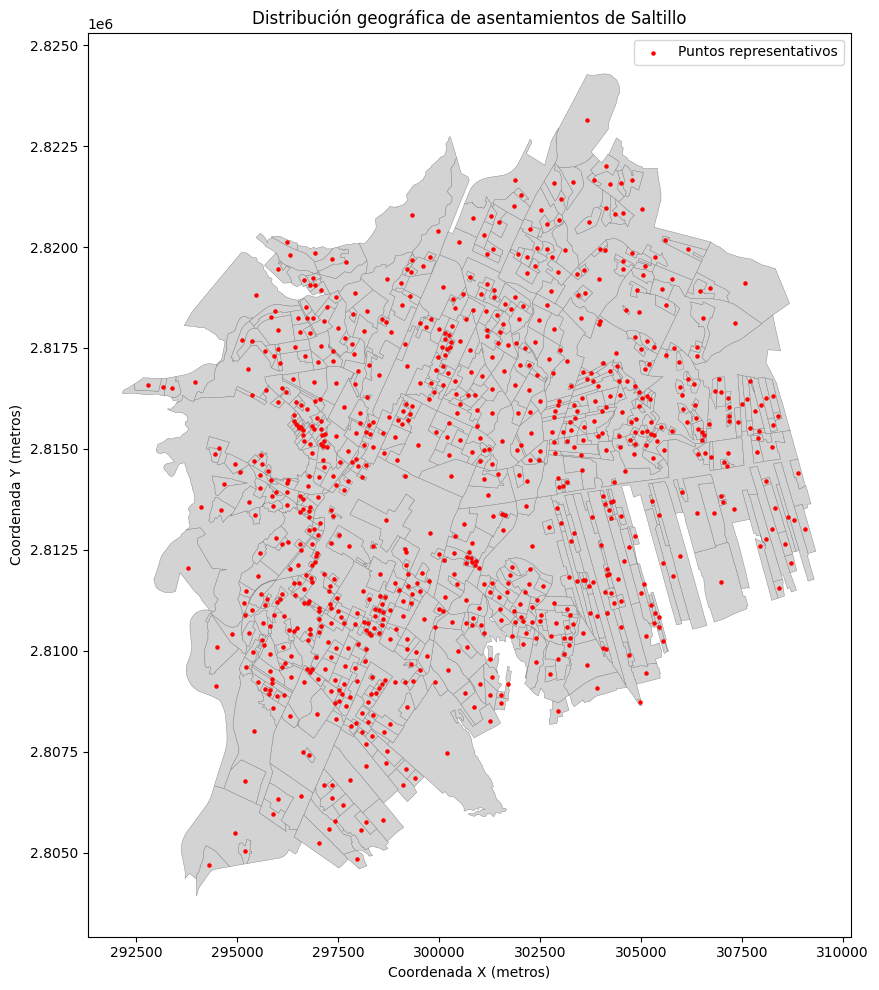

In [64]:
# ============================================================
# VISUALIZACIÓN DE CENTROIDES
# ============================================================

# Crear GeoDataFrame de puntos representativos
PUNTOS_GEO = gpd.GeoDataFrame(
    CENTROIDES.drop(
        columns=["geometry", "Centroide"]
    ),
    geometry="Punto_Representativo",
    crs=CENTROIDES.crs
)

fig, ax = plt.subplots(figsize=(11, 10))

# Dibujar polígonos
ASENTAMIENTOS_PROYECTADOS.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="gray",
    linewidth=0.3
)

# Dibujar puntos representativos
PUNTOS_GEO.plot(
    ax=ax,
    color="red",
    markersize=5,
    label="Puntos representativos"
)

ax.set_title(
    "Distribución geográfica de asentamientos de Saltillo"
)

ax.set_xlabel("Coordenada X (metros)")
ax.set_ylabel("Coordenada Y (metros)")
ax.set_aspect("equal")

ax.legend()
plt.tight_layout()
plt.show()

In [67]:
# ============================================================
# VINCULACIÓN GEOGRÁFICA CON LA DEMANDA DE RESIDUOS
# ============================================================

# ------------------------------------------------------------
# Obtener CVEASEN desde la clave geográfica del KML
# ------------------------------------------------------------
CENTROIDES["CVEASEN"] = pd.to_numeric(
    CENTROIDES["Name"].astype("string").str[-4:],
    errors="coerce"
)

# Validar identificadores
if CENTROIDES["CVEASEN"].isna().any():
    raise ValueError(
        "Existen asentamientos del KML sin identificador válido."
    )

if CENTROIDES["CVEASEN"].duplicated().any():
    raise ValueError(
        "Existen claves CVEASEN duplicadas en el KML."
    )

# ------------------------------------------------------------
# Unir puntos geográficos y demanda estimada
# ------------------------------------------------------------
ASENTAMIENTOS_CLUSTER = CENTROIDES.merge(
    DEMANDA_ASENTAMIENTOS[
        ["CVEASEN", "Poblacion_Original", "Demanda_Toneladas"]
    ],
    on="CVEASEN",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# Verificar asentamientos con y sin demanda
# ------------------------------------------------------------
CON_DEMANDA = ASENTAMIENTOS_CLUSTER[
    ASENTAMIENTOS_CLUSTER["Demanda_Toneladas"].notna()
].copy()

SIN_DEMANDA = ASENTAMIENTOS_CLUSTER[
    ASENTAMIENTOS_CLUSTER["Demanda_Toneladas"].isna()
].copy()

print("Asentamientos del KML:", len(ASENTAMIENTOS_CLUSTER))
print("Asentamientos con demanda:", len(CON_DEMANDA))
print("Asentamientos sin demanda:", len(SIN_DEMANDA))

print(
    "Demanda total de 2 días:",
    f"{CON_DEMANDA['Demanda_Toneladas'].sum():,.2f} toneladas"
)

display(
    ASENTAMIENTOS_CLUSTER[
        [
            "CVEASEN",
            "Coordenada_X",
            "Coordenada_Y",
            "Poblacion_Original",
            "Demanda_Toneladas"
        ]
    ].head(10)
)

Asentamientos del KML: 862
Asentamientos con demanda: 396
Asentamientos sin demanda: 466
Demanda total de 2 días: 625.26 toneladas


,CVEASEN,Coordenada_X,Coordenada_Y,Poblacion_Original,Demanda_Toneladas
0,495,295456.236483,2.818803e+06,NaN,NaN
1,882,293153.120170,2.816536e+06,NaN,NaN
2,838,294882.324174,2.810418e+06,NaN,NaN
3,731,298150.121808,2.817920e+06,1709.0,2.832363
4,100,297504.136500,2.817985e+06,NaN,NaN
5,599,296008.478834,2.817938e+06,NaN,NaN
6,520,293786.023022,2.812047e+06,NaN,NaN
7,406,296909.901569,2.816660e+06,NaN,NaN
8,653,295356.406888,2.816324e+06,NaN,NaN
9,535,293964.518007,2.816657e+06,NaN,NaN


In [68]:
# ============================================================
# PREPARACIÓN FINAL DE DATOS PARA CLUSTERIZACIÓN
# ============================================================

# ------------------------------------------------------------
# Seleccionar únicamente asentamientos del turno vespertino
# ------------------------------------------------------------
DATOS_CLUSTER = ASENTAMIENTOS_CLUSTER[
    ASENTAMIENTOS_CLUSTER["Demanda_Toneladas"].notna()
].copy()

# ------------------------------------------------------------
# Validar coordenadas y demanda
# ------------------------------------------------------------
if DATOS_CLUSTER[
    ["Coordenada_X", "Coordenada_Y", "Demanda_Toneladas"]
].isna().any().any():
    raise ValueError(
        "Existen asentamientos con información incompleta."
    )

if (DATOS_CLUSTER["Demanda_Toneladas"] < 0).any():
    raise ValueError(
        "Existen asentamientos con demanda negativa."
    )

# ------------------------------------------------------------
# Preparar variables para K-Means
# ------------------------------------------------------------
COORDENADAS_CLUSTER = DATOS_CLUSTER[
    ["Coordenada_X", "Coordenada_Y"]
].to_numpy()

PESOS_CLUSTER = DATOS_CLUSTER[
    "Demanda_Toneladas"
].to_numpy()

# ------------------------------------------------------------
# Resultados
# ------------------------------------------------------------
print("Asentamientos para clustering:", len(DATOS_CLUSTER))

print(
    "Demanda total estimada:",
    f"{PESOS_CLUSTER.sum():,.2f} toneladas"
)

print(
    "Sistema de coordenadas:",
    DATOS_CLUSTER.crs
)

Asentamientos para clustering: 396
Demanda total estimada: 625.26 toneladas
Sistema de coordenadas: EPSG:32614


___
## 5. Clusterización geográfica mediante K-Means

Se aplica el algoritmo de aprendizaje no supervisado K-Means a los asentamientos del turno vespertino, utilizando sus coordenadas geográficas proyectadas y la demanda estimada de residuos acumulados durante dos días

Se evalúan agrupamientos de 2 a 5 clústeres mediante el coeficiente de silueta y la distribución de toneladas entre grupos. Se presta especial atención a la división en dos zonas, Norte y Sur

In [76]:
# ============================================================
# EVALUACIÓN DE K-MEANS (K = 2 A 5)
# ============================================================

RESULTADOS_CLUSTER = []
MODELOS_CLUSTER = {}

for k in range(2, 6):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(
        COORDENADAS_CLUSTER,
        sample_weight=PESOS_CLUSTER
    )

    # Silueta basada en las distancias geográficas
    silueta = silhouette_score(
        COORDENADAS_CLUSTER,
        etiquetas
    )

    # Toneladas acumuladas en cada grupo
    cargas = np.bincount(
        etiquetas,
        weights=PESOS_CLUSTER,
        minlength=k
    )

    carga_ideal = cargas.sum() / k

    # Mayor desviación porcentual respecto a la carga ideal
    desequilibrio = (
        np.max(np.abs(cargas - carga_ideal))
        / carga_ideal * 100
    )

    RESULTADOS_CLUSTER.append({
        "K": k,
        "Silhouette": silueta,
        "Carga_Min_Ton": cargas.min(),
        "Carga_Max_Ton": cargas.max(),
        "Desviacion_Max_Pct": desequilibrio,
        "Inercia_Ponderada": modelo.inertia_
    })

    MODELOS_CLUSTER[k] = modelo

RESULTADOS_CLUSTER = pd.DataFrame(
    RESULTADOS_CLUSTER
)

display(RESULTADOS_CLUSTER.round(3))

,K,Silhouette,Carga_Min_Ton,Carga_Max_Ton,Desviacion_Max_Pct,Inercia_Ponderada
0,2,0.479,292.816,332.444,6.338,6.664285e+09
1,3,0.415,178.348,262.833,26.107,4.293616e+09
2,4,0.354,134.011,181.263,15.960,3.227297e+09
3,5,0.294,92.850,201.194,60.888,2.625392e+09


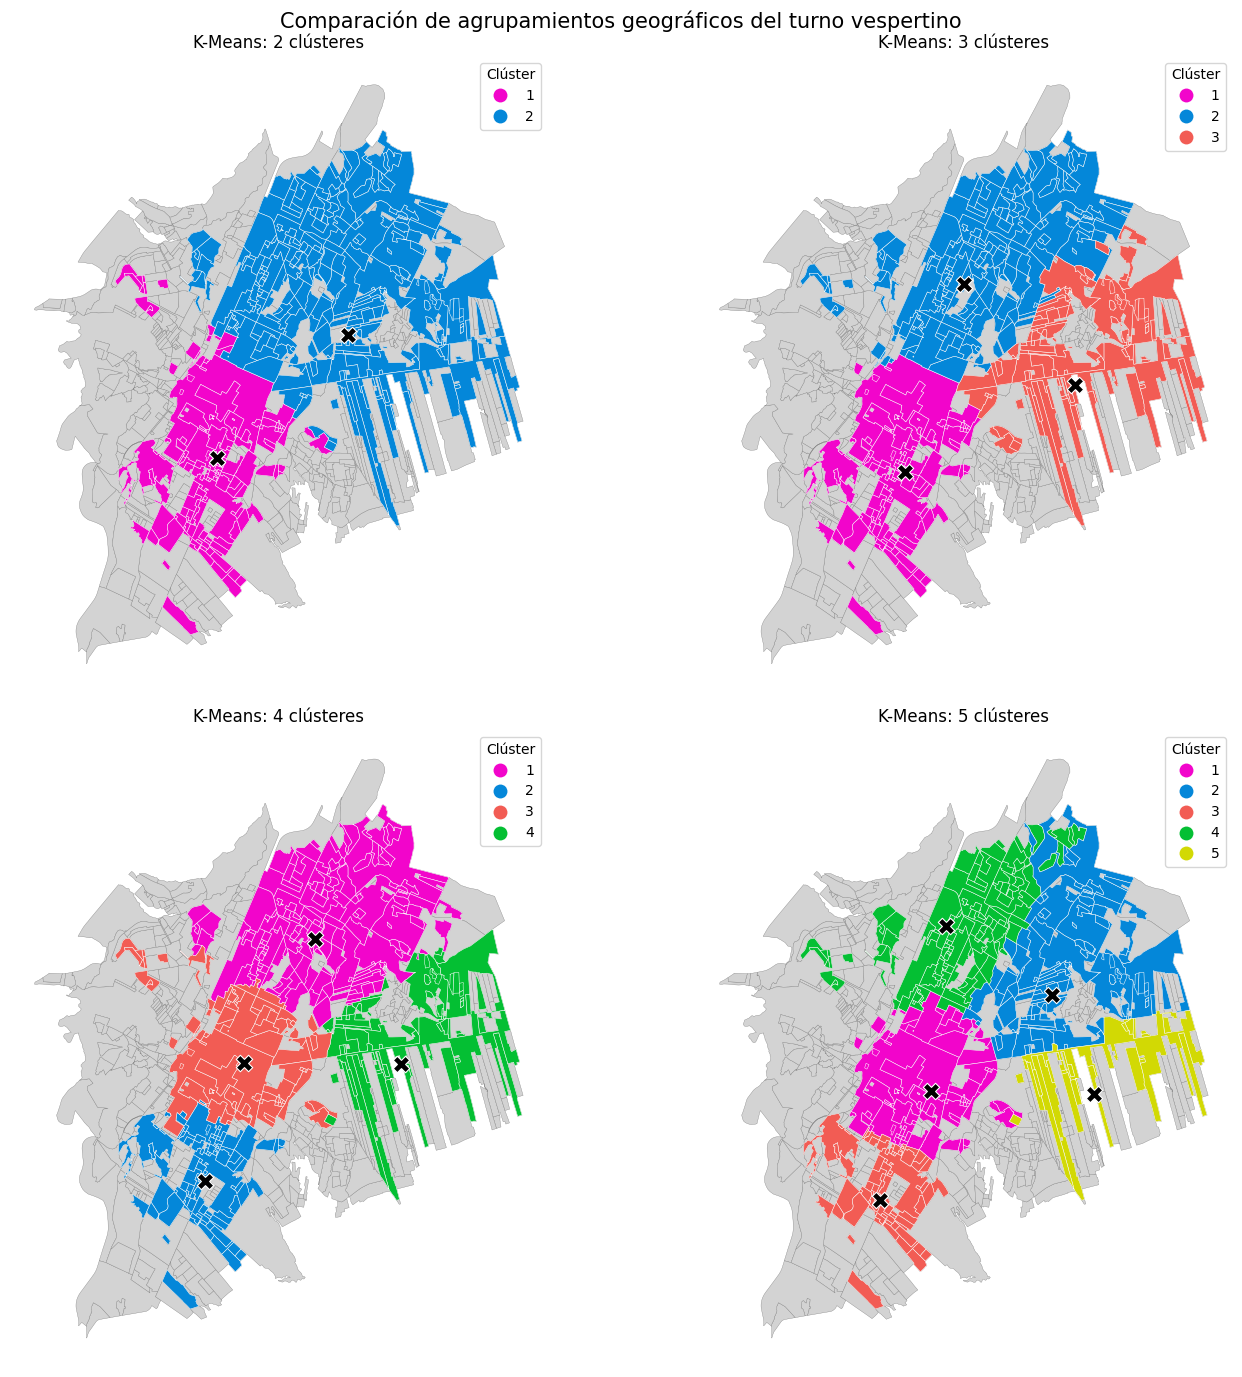

In [88]:
# ============================================================
# VISUALIZACIÓN DE K-MEANS (K = 2 A 5)
# ============================================================

from matplotlib.colors import ListedColormap

COLORES_CLUSTERS = [
    "#F205CB",  # Cluster 1 - Rosa
    "#0487D9",  # Cluster 2 - Azul
    "#F25C54",  # Cluster 3 - Rojo anaranjado
    "#04BF33",  # Cluster 4 - Verde
    "#D2D904"   # Cluster 5 - Amarillo
]

fig, ejes = plt.subplots(
    2, 2,
    figsize=(15, 14)
)

# ------------------------------------------------------------
# Dibujar cada escenario de clusterización
# ------------------------------------------------------------
for ax, k in zip(ejes.flat, range(2, 6)):

    modelo = MODELOS_CLUSTER[k]

    mapa = DATOS_CLUSTER.copy()

    # Numerar clústeres a partir de 1
    mapa["Cluster"] = modelo.labels_ + 1

    # --------------------------------------------------------
    # Dibujar todos los asentamientos como fondo
    # --------------------------------------------------------
    ASENTAMIENTOS_PROYECTADOS.plot(
        ax=ax,
        facecolor="lightgray",
        edgecolor="gray",
        linewidth=0.25
    )

    # --------------------------------------------------------
    # Colorear únicamente asentamientos vespertinos
    # --------------------------------------------------------
    mapa.plot(
        column="Cluster",
        ax=ax,
        categorical=True,
        cmap=ListedColormap(COLORES_CLUSTERS[:k]),
        edgecolor="white",
        linewidth=0.35,
        legend=True,
        legend_kwds={"title": "Clúster"}
    )

    # --------------------------------------------------------
    # Centros de los clústeres
    # --------------------------------------------------------
    ax.scatter(
        modelo.cluster_centers_[:, 0],
        modelo.cluster_centers_[:, 1],
        marker="X",
        s=140,
        c="black",
        edgecolors="white",
        linewidths=0.8
    )

    ax.set_title(f"K-Means: {k} clústeres")
    ax.set_aspect("equal")
    ax.axis("off")

plt.suptitle(
    "Comparación de agrupamientos geográficos del turno vespertino",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [78]:
# ============================================================
# DIVISIÓN PRINCIPAL: NORTE Y SUR
# ============================================================

MODELO_NORTE_SUR = MODELOS_CLUSTER[2]

ZONAS_CLUSTER = DATOS_CLUSTER.copy()

ZONAS_CLUSTER["Cluster"] = MODELO_NORTE_SUR.labels_

# ------------------------------------------------------------
# Identificar qué clúster está más al norte
# ------------------------------------------------------------
PROMEDIO_NORTE = (
    ZONAS_CLUSTER
    .groupby("Cluster")["Coordenada_Y"]
    .mean()
)

CLUSTER_NORTE = PROMEDIO_NORTE.idxmax()
CLUSTER_SUR = PROMEDIO_NORTE.idxmin()

ZONAS_CLUSTER["Zona_Propuesta"] = (
    ZONAS_CLUSTER["Cluster"].map({
        CLUSTER_NORTE: "Norte",
        CLUSTER_SUR: "Sur"
    })
)

# ------------------------------------------------------------
# Resumen por zona
# ------------------------------------------------------------
RESUMEN_ZONAS = (
    ZONAS_CLUSTER
    .groupby("Zona_Propuesta")
    .agg(
        Asentamientos=("CVEASEN", "nunique"),
        Poblacion=("Poblacion_Original", "sum"),
        Demanda_Toneladas=("Demanda_Toneladas", "sum")
    )
    .reset_index()
)

RESUMEN_ZONAS["Porcentaje_Demanda"] = (
    RESUMEN_ZONAS["Demanda_Toneladas"]
    / RESUMEN_ZONAS["Demanda_Toneladas"].sum()
    * 100
)

# ------------------------------------------------------------
# Diferencia de demanda entre las dos zonas
# ------------------------------------------------------------
CARGA_NORTE = RESUMEN_ZONAS.loc[
    RESUMEN_ZONAS["Zona_Propuesta"] == "Norte",
    "Demanda_Toneladas"
].iloc[0]

CARGA_SUR = RESUMEN_ZONAS.loc[
    RESUMEN_ZONAS["Zona_Propuesta"] == "Sur",
    "Demanda_Toneladas"
].iloc[0]

DIFERENCIA_TONELADAS = abs(
    CARGA_NORTE - CARGA_SUR
)

DESEQUILIBRIO_ZONAS = (
    DIFERENCIA_TONELADAS
    / RESUMEN_ZONAS["Demanda_Toneladas"].sum()
    * 100
)

display(RESUMEN_ZONAS.round(2))

print(
    f"Diferencia entre zonas: "
    f"{DIFERENCIA_TONELADAS:.2f} toneladas"
)

print(
    f"Desequilibrio respecto al total: "
    f"{DESEQUILIBRIO_ZONAS:.2f}%"
)

,Zona_Propuesta,Asentamientos,Poblacion,Demanda_Toneladas,Porcentaje_Demanda
0,Norte,265,200591.0,332.44,53.17
1,Sur,131,176680.0,292.82,46.83


Diferencia entre zonas: 39.63 toneladas
Desequilibrio respecto al total: 6.34%


C:\Users\david\AppData\Local\Temp\ipykernel_37660\447528081.py:65: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend()


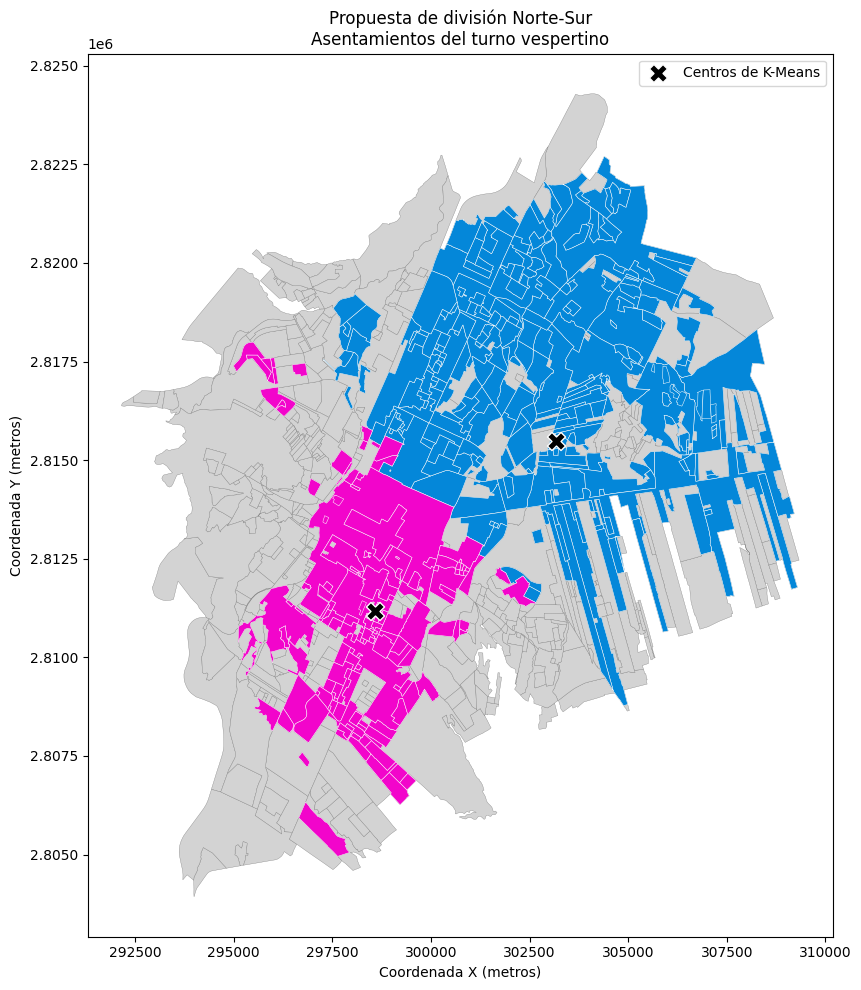

In [90]:
# ============================================================
# MAPA DE LA DIVISIÓN NORTE-SUR
# ============================================================

fig, ax = plt.subplots(figsize=(11, 10))

COLORES_ZONAS = {
    "Norte": "#0487D9",
    "Sur": "#F205CB"
}

# ------------------------------------------------------------
# Dibujar todos los asentamientos como fondo
# ------------------------------------------------------------
ASENTAMIENTOS_PROYECTADOS.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="gray",
    linewidth=0.25,
    label="Otros asentamientos"
)

# ------------------------------------------------------------
# Colorear únicamente los asentamientos vespertinos
# ------------------------------------------------------------
for zona in ["Norte", "Sur"]:

    subconjunto = ZONAS_CLUSTER[
        ZONAS_CLUSTER["Zona_Propuesta"] == zona
    ]

    subconjunto.plot(
        ax=ax,
        color=COLORES_ZONAS[zona],
        edgecolor="white",
        linewidth=0.35,
        label=zona
    )

# ------------------------------------------------------------
# Dibujar los centros de K-Means
# ------------------------------------------------------------
ax.scatter(
    MODELO_NORTE_SUR.cluster_centers_[:, 0],
    MODELO_NORTE_SUR.cluster_centers_[:, 1],
    marker="X",
    s=170,
    c="black",
    edgecolors="white",
    linewidth=1,
    label="Centros de K-Means"
)

# ------------------------------------------------------------
# Configurar gráfica
# ------------------------------------------------------------
ax.set_title(
    "Propuesta de división Norte-Sur\n"
    "Asentamientos del turno vespertino"
)

ax.set_xlabel("Coordenada X (metros)")
ax.set_ylabel("Coordenada Y (metros)")
ax.set_aspect("equal")
ax.legend()

plt.tight_layout()
plt.show()

In [81]:
# ============================================================
# VERIFICACIÓN DE CONTINUIDAD GEOGRÁFICA
# ============================================================

def componentes_geograficos(geodatos):

    geodatos = geodatos.reset_index(drop=True).copy()
    geometrias = geodatos.geometry
    indice_espacial = geodatos.sindex

    vecinos = {
        i: set()
        for i in range(len(geodatos))
    }

    # Construir grafo de adyacencia entre polígonos
    for i, geometria in enumerate(geometrias):

        candidatos = indice_espacial.query(
            geometria,
            predicate="intersects"
        )

        for j in candidatos:

            j = int(j)

            if j <= i:
                continue

            frontera_compartida = (
                geometria.boundary
                .intersection(geometrias.iloc[j].boundary)
            )

            if frontera_compartida.length > 0.01:
                vecinos[i].add(j)
                vecinos[j].add(i)

    # Buscar componentes conectados
    visitados = set()
    componentes = []

    for inicio in range(len(geodatos)):

        if inicio in visitados:
            continue

        pendientes = [inicio]
        visitados.add(inicio)
        componente = []

        while pendientes:

            actual = pendientes.pop()
            componente.append(actual)

            for vecino in vecinos[actual]:

                if vecino not in visitados:
                    visitados.add(vecino)
                    pendientes.append(vecino)

        componentes.append(componente)

    return sorted(
        componentes,
        key=len,
        reverse=True
    )


RESULTADOS_CONTINUIDAD = []

for zona in ["Norte", "Sur"]:

    subconjunto = ZONAS_CLUSTER[
        ZONAS_CLUSTER["Zona_Propuesta"] == zona
    ].copy()

    componentes = componentes_geograficos(subconjunto)

    RESULTADOS_CONTINUIDAD.append({
        "Zona": zona,
        "Componentes_Geograficos": len(componentes),
        "Asentamientos_Componente_Principal": len(componentes[0]),
        "Asentamientos_Aislados": (
            len(subconjunto) - len(componentes[0])
        )
    })

CONTINUIDAD_ZONAS = pd.DataFrame(
    RESULTADOS_CONTINUIDAD
)

display(CONTINUIDAD_ZONAS)

,Zona,Componentes_Geograficos,Asentamientos_Componente_Principal,Asentamientos_Aislados
0,Norte,22,223,42
1,Sur,15,107,24


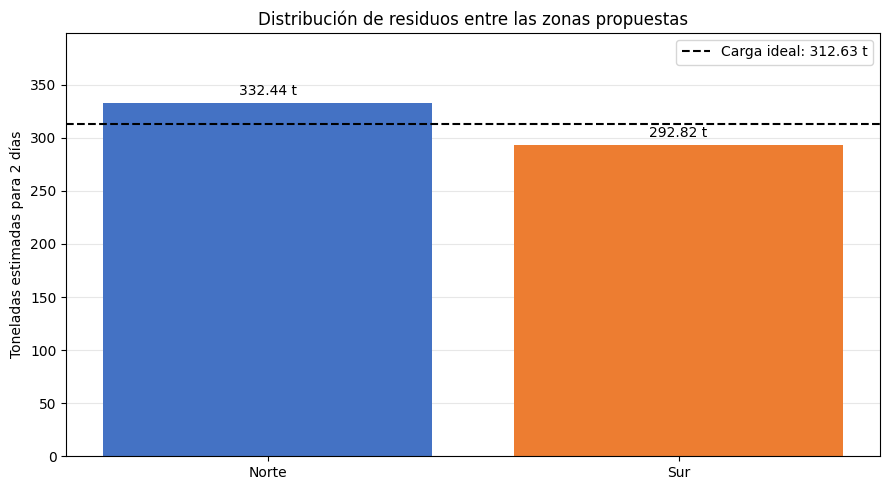

In [ ]:
# ============================================================
# COMPARACIÓN DE DEMANDA ENTRE NORTE Y SUR
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

zonas = RESUMEN_ZONAS["Zona_Propuesta"]
toneladas = RESUMEN_ZONAS["Demanda_Toneladas"]

colores = [
    COLORES_ZONAS[zona]
    for zona in zonas
]

barras = ax.bar(
    zonas,
    toneladas,
    color=colores
)

ax.bar_label(
    barras,
    fmt="%.2f t",
    padding=4
)

CARGA_IDEAL = toneladas.sum() / 2

ax.axhline(
    CARGA_IDEAL,
    linestyle="--",
    color="black",
    label=f"Carga ideal: {CARGA_IDEAL:.2f} t"
)

ax.set_title("Distribución de residuos entre las zonas propuestas")
ax.set_ylabel("Toneladas estimadas para 2 días")
ax.set_ylim(0, max(toneladas.max(), CARGA_IDEAL) * 1.2)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend()

plt.tight_layout()
plt.show()